In [1]:
!pip install transformers arabert prep
!pip install farasapy
!pip install sklearn


  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 185.0/185.0 kB 4.7 MB/s eta 0:00:0000:01
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 179.3/179.3 kB 7.1 MB/s eta 0:00:00
  Created wheel for emoji: filename=emoji-1.4.2-py3-none-any.whl size=186456 sha256=b1e5b94d2aa7b8f1c5210f6e92180e21095301a1cabcfcf7b0ce4e80fa6e88ab
  Stored in directory: /root/.cache/pip/wheels/94/08/b4/78657b1541bb704b088317b52429ee4016d9888fe47dbb130f
  Created wheel for prep: filename=prep-0.1.10-py3-none-any.whl size=8435 sha256=8519238c1255bf29b561e40166b9046604e8e5fd3a9fe2603024d929e241359c
  Stored in directory: /root/.cache/pip/wheels/f2/c7/53/ffa094d7f2d271b2b00be6629cd4cfed5d011c6448ed392ac9
Successfully built emoji prep
  Attempting uninstall: emoji
    Found existing installation: emoji 2.15.0
    Uninstalling emoji-2.15.0:
      Successfully uninstalled emoji-2.15.0
  error: subprocess-exited-with-error
  
  × python setup.py e

In [4]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
df = pd.read_csv("/kaggle/input/arabic-sentiment-analysis-dataset-ss2030-dataset/Arabic Sentiment Analysis Dataset - SS2030.csv")
df.head() 


,text,Sentiment
0,حقوق المرأة 💚💚💚 https://t.co/Mzf90Ta5g1,1
1,RT @___IHAVENOIDEA: حقوق المرأة في الإسلام. ht...,1
2,RT @saud_talep: Retweeted لجنة التنمية بشبرا (...,1
3,RT @MojKsa: حقوق المرأة التي تضمنها لها وزارة ...,1
4,RT @abm112211: ولي امر الزوجة او ولي الزوجة او...,1


In [7]:
def clean_arabic(text):
    text = str(text)
    text = re.sub(r"http\S+", "", text)  # remove URLs
    text = re.sub(r"@\w+", "", text)     # remove mentions
    text = re.sub(r"#", "", text)        # remove hashtag symbol
    text = re.sub(r"[^\u0600-\u06FF\s]", " ", text)  # keep Arabic only
    text = re.sub(r"\s+", " ", text)     # remove extra spaces
    return text.strip()

df['clean_text'] = df['text'].apply(clean_arabic)
df.head()


,text,Sentiment,clean_text
0,حقوق المرأة 💚💚💚 https://t.co/Mzf90Ta5g1,1,حقوق المرأة
1,RT @___IHAVENOIDEA: حقوق المرأة في الإسلام. ht...,1,حقوق المرأة في الإسلام
2,RT @saud_talep: Retweeted لجنة التنمية بشبرا (...,1,لجنة التنمية بشبرا ما زال التسجيل مستمر في دور...
3,RT @MojKsa: حقوق المرأة التي تضمنها لها وزارة ...,1,حقوق المرأة التي تضمنها لها وزارة العدل
4,RT @abm112211: ولي امر الزوجة او ولي الزوجة او...,1,ولي امر الزوجة او ولي الزوجة او ولي المراة من ...


In [12]:
import re

def clean_arabic(text):
    text = str(text)
    text = re.sub(r"http\S+", "", text)       # remove URLs
    text = re.sub(r"@\w+", "", text)          # remove mentions
    text = re.sub(r"#[^\s]+", "", text)       # remove hashtags
    text = re.sub(r"[^\u0600-\u06FF\s]", " ", text)  # keep Arabic only
    text = re.sub(r"\s+", " ", text)          # clean spaces
    return text.strip()

df['clean_text'] = df['text'].apply(clean_arabic)
df.head()


/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: invalid value encountered in greater
  has_large_values = (abs_vals > 1e6).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in less
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in greater
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()


,text,Sentiment,clean_text,label
0,حقوق المرأة 💚💚💚 https://t.co/Mzf90Ta5g1,1,حقوق المرأة,NaN
1,RT @___IHAVENOIDEA: حقوق المرأة في الإسلام. ht...,1,حقوق المرأة في الإسلام,NaN
2,RT @saud_talep: Retweeted لجنة التنمية بشبرا (...,1,لجنة التنمية بشبرا ما زال التسجيل مستمر في دور...,NaN
3,RT @MojKsa: حقوق المرأة التي تضمنها لها وزارة ...,1,حقوق المرأة التي تضمنها لها وزارة العدل,NaN
4,RT @abm112211: ولي امر الزوجة او ولي الزوجة او...,1,ولي امر الزوجة او ولي الزوجة او ولي المراة من ...,NaN


In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df['clean_text'], df['Sentiment'], test_size=0.2, random_state=42, stratify=df['Sentiment'])


In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1,2))
X_train_vec = tfidf.fit_transform(X_train)
X_test_vec = tfidf.transform(X_test)

lr = LogisticRegression(max_iter=2000)
lr.fit(X_train_vec, y_train)

y_pred_lr = lr.predict(X_test_vec)


In [15]:
from sklearn.metrics import accuracy_score, classification_report

print("LR Accuracy:", accuracy_score(y_test, y_pred_lr))
print(classification_report(y_test, y_pred_lr))


LR Accuracy: 0.8202115158636898
              precision    recall  f1-score   support

           0       0.86      0.69      0.77       363
           1       0.80      0.92      0.85       488

    accuracy                           0.82       851
   macro avg       0.83      0.80      0.81       851
weighted avg       0.83      0.82      0.82       851



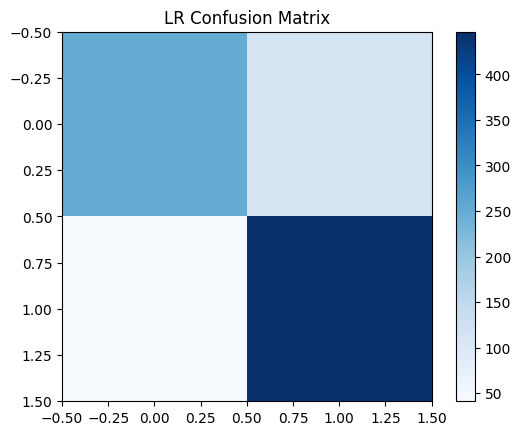

In [16]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_lr)
plt.imshow(cm, cmap="Blues")
plt.title("LR Confusion Matrix")
plt.colorbar()
plt.show()


  Using cached sklearn-0.0.post12.tar.gz (2.6 kB)
  error: subprocess-exited-with-error
  
  × python setup.py egg_info did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Preparing metadata (setup.py) ... error
error: metadata-generation-failed

× Encountered error while generating package metadata.
╰─> See above for output.

note: This is an issue with the package mentioned above, not pip.
hint: See above for details.


config.json:   0%|          | 0.00/491 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/62.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/445M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at asafaya/bert-base-arabic and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Using the `WANDB_DISABLED` environment variable is deprecated and will be removed in v5. Use the --report_to flag to control the integrations used for logging result (for instance --report_to none).
/usr/local/lib/python3.11/dist-packages/torch/nn/parallel/_functions.py:70: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  warnings.warn(


Epoch,Training Loss,Validation Loss
1,0.352900,0.365357
2,0.227100,0.321560


Accuracy: 0.8554641598119859
              precision    recall  f1-score   support

           0       0.83      0.83      0.83       363
           1       0.87      0.88      0.87       488

    accuracy                           0.86       851
   macro avg       0.85      0.85      0.85       851
weighted avg       0.86      0.86      0.86       851



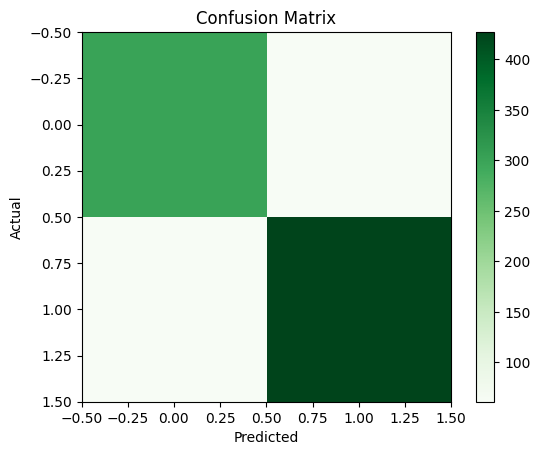

In [27]:
!pip install transformers sklearn arabert

# =========================================================
# 1) IMPORTS
# =========================================================
import pandas as pd
import numpy as np
import re
import torch
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    AutoConfig,
    TrainingArguments,
    Trainer
)

# Disable W&B
import os
os.environ["WANDB_DISABLED"] = "true"

# =========================================================
# 2) LOAD DATA
# =========================================================
df = pd.read_csv("/kaggle/input/arabic-sentiment-analysis-dataset-ss2030-dataset/Arabic Sentiment Analysis Dataset - SS2030.csv")

# =========================================================
# 3) CLEAN ARABIC TEXT
# =========================================================
def clean_arabic(text):
    text = str(text)
    text = re.sub(r"http\S+", "", text)
    text = re.sub(r"@\w+", "", text)
    text = re.sub(r"#[^\s]+", "", text)
    text = re.sub(r"[^\u0600-\u06FF\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["clean_text"] = df["text"].apply(clean_arabic)

# =========================================================
# 4) TRAIN / TEST SPLIT
# =========================================================
X_train, X_test, y_train, y_test = train_test_split(
    df["clean_text"], df["Sentiment"],
    test_size=0.2, random_state=42, stratify=df["Sentiment"]
)

# =========================================================
# 5) LOAD FAST ARABIC BERT MODEL
# =========================================================
model_name = "asafaya/bert-base-arabic"

config = AutoConfig.from_pretrained(model_name, num_labels=2)
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    config=config,
    ignore_mismatched_sizes=True
)

# =========================================================
# 6) DATASET CLASS
# =========================================================
class SentimentDataset(torch.utils.data.Dataset):
    def __init__(self, texts, labels):
        self.texts = list(texts)
        self.labels = list(labels)

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        enc = tokenizer(
            self.texts[idx],
            truncation=True,
            padding="max_length",
            max_length=128
        )
        enc = {k: torch.tensor(v) for k, v in enc.items()}
        enc["labels"] = torch.tensor(int(self.labels[idx]))
        return enc

train_ds = SentimentDataset(X_train, y_train)
test_ds = SentimentDataset(X_test, y_test)

# =========================================================
# 7) TRAINING ARGUMENTS (FAST)
# =========================================================
training_args = TrainingArguments(
    output_dir="./results",
    eval_strategy="epoch",
    save_strategy="no",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=2,
    weight_decay=0.01,
    logging_steps=30,
    run_name="fast-arabic-bert"
)

# =========================================================
# 8) TRAINER
# =========================================================
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=test_ds
)

# =========================================================
# 9) TRAIN MODEL
# =========================================================
trainer.train()

# =========================================================
# 10) EVALUATE MODEL
# =========================================================
preds = trainer.predict(test_ds)
y_pred = preds.predictions.argmax(axis=1)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

# =========================================================
# 11) CONFUSION MATRIX
# =========================================================
cm = confusion_matrix(y_test, y_pred)
plt.imshow(cm, cmap="Greens")
plt.title("Confusion Matrix")
plt.colorbar()
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()
